# Chest X-ray Pneumonia Detection | YOLOv8, PyTorch

- Task: find pneumonia areas (boxes) on chest X-rays (RSNA, 26,684 images, 22.5% with pneumonia).
- Baselines: "always no pneumonia" (accuracy 0.775, recall 0); two fixed median boxes on every image (precision 0.028, recall 0.159 at IoU 0.5).
- ResNet18 classifier (256 px): val PR-AUC 0.67–0.69 over two seeds. Almost all false alarms come from "No Lung Opacity / Not Normal" images.
- YOLOv8n detector (512 px): precision 0.354, recall 0.476 at confidence 0.1 (IoU 0.5), far above the fixed-box baseline.
- The notes were written after an earlier run. GPU training is not fully deterministic,
  so numbers in this run may differ slightly (most of all for the YOLO detector).

In [1]:
import os, random
import numpy as np
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/rsna-pneumonia-detection-challenge"
SEED = 42
random.seed(SEED); np.random.seed(SEED)

print("Files in data dir:", sorted(os.listdir(DATA_DIR)))
print("Train images:", len(os.listdir(f"{DATA_DIR}/stage_2_train_images")))

import urllib.request
_ = urllib.request.urlopen("https://pypi.org", timeout=10)  # fail fast if Internet is off

Files in data dir: ['GCP Credits Request Link - RSNA.txt', 'stage_2_detailed_class_info.csv', 'stage_2_sample_submission.csv', 'stage_2_test_images', 'stage_2_train_images', 'stage_2_train_labels.csv']
Train images: 26684


In [2]:
import pandas as pd
import numpy as np

SEED = 42
np.random.seed(SEED)

labels = pd.read_csv(f"{DATA_DIR}/stage_2_train_labels.csv")

n_rows = len(labels)
n_images = labels["patientId"].nunique()
share_pos = labels.groupby("patientId")["Target"].max().mean()

print("rows:", n_rows)
print("unique images:", n_images)
print("share of images with pneumonia:", round(share_pos, 4))

rows: 30227
unique images: 26684
share of images with pneumonia: 0.2253


In [3]:
pos = labels[labels["Target"] == 1]
boxes_per_image = pos.groupby("patientId").size()

print(boxes_per_image.value_counts().sort_index())
print("max boxes on one image:", boxes_per_image.max())

1    2614
2    3266
3     119
4      13
Name: count, dtype: int64
max boxes on one image: 4


In [4]:
info = pd.read_csv(f"{DATA_DIR}/stage_2_detailed_class_info.csv")

# the file repeats a row for every box, so keep one row per image
info_per_image = info.drop_duplicates("patientId")

print(len(info_per_image))
print(info_per_image["class"].value_counts())

26684
class
No Lung Opacity / Not Normal    11821
Normal                           8851
Lung Opacity                     6012
Name: count, dtype: int64


## 1: Labels EDA

- **Observation:** 30227 rows for 26684 unique images (one row per box). Pneumonia on 6012 images (22.53%), each with 1-4 boxes (1.59 on average, most often 2). Of the 20672 images without pneumonia, 8851 are Normal (42.82%) and 11821 are "No Lung Opacity / Not Normal" (57.18%).
- **Decision:** Do not rely on accuracy: always predicting "no pneumonia" gives 0.7747 accuracy and finds no sick patients. Track recall, precision and PR-AUC. Split by patientId with a fixed seed.
- **Result:** Class balance over all images: Normal 33.17%, Not Normal 44.30%, Lung Opacity 22.53%. Hypothesis (not tested yet): the Not Normal class may be confused with pneumonia. Seed 42.

In [5]:
# list of all image ids, used by the checks below
all_ids = labels["patientId"].unique().tolist()
print(len(all_ids))

26684


In [6]:
import pydicom

TRAIN_DIR = f"{DATA_DIR}/stage_2_train_images"
sick_id = pos["patientId"].iloc[0]

dcm = pydicom.dcmread(f"{TRAIN_DIR}/{sick_id}.dcm")
img = dcm.pixel_array

print("shape:", img.shape)
print("dtype:", img.dtype)
print("min / max:", img.min(), img.max())

shape: (1024, 1024)
dtype: uint8
min / max: 0 255


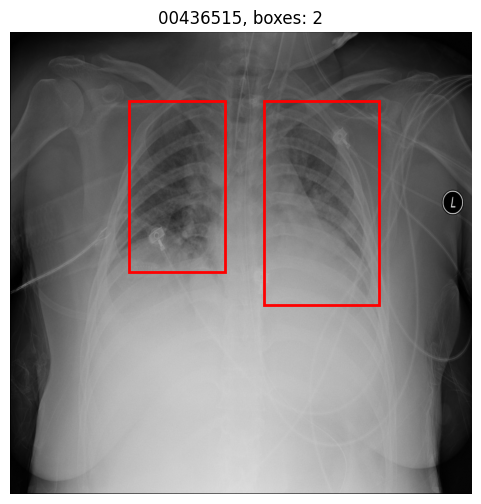

       x      y  width  height
4  264.0  152.0  213.0   379.0
5  562.0  152.0  256.0   453.0


In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

boxes = pos[pos["patientId"] == sick_id]

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")
for _, r in boxes.iterrows():
    # (x, y) is the top-left corner of the box
    rect = patches.Rectangle((r["x"], r["y"]), r["width"], r["height"],
                             fill=False, edgecolor="red", linewidth=2)
    ax.add_patch(rect)
ax.set_title(f"{sick_id[:8]}, boxes: {len(boxes)}")
ax.axis("off")
plt.show()

print(boxes[["x", "y", "width", "height"]])

In [8]:
from collections import Counter
from tqdm import tqdm

size_counts = Counter()
bad_files = []

for pid in tqdm(all_ids):
    try:
        # read only the header, not the pixels
        h = pydicom.dcmread(f"{TRAIN_DIR}/{pid}.dcm", stop_before_pixels=True)
        size_counts[(int(h.Rows), int(h.Columns))] += 1
    except Exception as e:
        bad_files.append((pid, str(e)))

print(size_counts)
print("checked:", sum(size_counts.values()), "of", len(all_ids))
print("unreadable files:", len(bad_files))

100%|██████████| 26684/26684 [03:35<00:00, 123.84it/s]

Counter({(1024, 1024): 26684})
checked: 26684 of 26684
unreadable files: 0


## 2: Images

- **Observation:** DICOM images are single-channel uint8 (0-255). A header check of all 26684 train images gave 1024x1024 for every file, with 0 unreadable files. On the example image with 2 boxes (213x379 and 256x453 px) the boxes cover about 7.70% and 11.06% of the image area, one box per lung. Boxes are coarse rectangles, and tubes and wires are visible on the image.
- **Decision:** Treat all images as 1024x1024. When converting to smaller PNG files, scale the boxes by the same factor as the image.
- **Result:** Sizes come from DICOM headers (not from decoding every pixel array). Not checked yet: brightness across images. Hypothesis (not tested): tubes and wires may distract a model.

In [9]:
from sklearn.model_selection import train_test_split

SEED = 42

# one row per image: 1 if pneumonia, else 0
per_image = labels.groupby("patientId")["Target"].max().reset_index()

train_df, val_df = train_test_split(
    per_image, test_size=0.2, random_state=SEED, shuffle=True
)

print("train:", len(train_df), "share sick:", round(train_df["Target"].mean(), 4))
print("val:  ", len(val_df), "share sick:", round(val_df["Target"].mean(), 4))

train: 21347 share sick: 0.2237
val:   5337 share sick: 0.2316


In [10]:
# one row per image with its 3-way class; Target = 1 only for "Lung Opacity"
per_image = info_per_image[["patientId", "class"]].copy()
per_image["Target"] = (per_image["class"] == "Lung Opacity").astype(int)
assert per_image["Target"].sum() == 6012  # same as the pneumonia count from the labels file

train_df, val_df = train_test_split(
    per_image, test_size=0.2, random_state=SEED, shuffle=True,
    stratify=per_image["class"],
)

print("train:", len(train_df), "val:", len(val_df))
print("sick share, train:", round(train_df["Target"].mean(), 4))
print("sick share, val:  ", round(val_df["Target"].mean(), 4))
print(val_df["class"].value_counts(normalize=True).round(4))

train_df.to_csv("train_split.csv", index=False)
val_df.to_csv("val_split.csv", index=False)

train: 21347 val: 5337
sick share, train: 0.2253
sick share, val:   0.2254
class
No Lung Opacity / Not Normal    0.4429
Normal                          0.3316
Lung Opacity                    0.2254
Name: proportion, dtype: float64


## 3: Train/validation split

- **Observation:** A plain random 80/20 split (seed 42) gave a sick share of 0.2237 in train and 0.2316 in val, against 0.2253 overall. The gap is within random noise.
- **Decision:** Re-split with stratification on the 3-way class (seed 42) and save to train_split.csv and val_split.csv. All experiments reuse these files. The split is by image, since each patientId is one image.
- **Result:** train 21347 / val 5337 images. Sick share 0.2253 / 0.2254. Val class shares: Not Normal 0.4429, Normal 0.3316, Lung Opacity 0.2254. Limitations: we cannot verify that one person has no several patientIds, and val has only about 1203 sick images, so small metric differences may be noise.

In [11]:
import os
from PIL import Image
from tqdm import tqdm

OUT_DIR = "/kaggle/working/png512"
os.makedirs(OUT_DIR, exist_ok=True)

for pid in tqdm(all_ids):
    out_path = f"{OUT_DIR}/{pid}.png"
    if os.path.exists(out_path):  # skip finished files, so a restart continues where it stopped
        continue
    arr = pydicom.dcmread(f"{TRAIN_DIR}/{pid}.dcm").pixel_array
    assert arr.shape == (1024, 1024)
    tmp_path = out_path + ".tmp"
    Image.fromarray(arr).resize((512, 512), Image.BILINEAR).save(tmp_path, format="PNG")
    os.replace(tmp_path, out_path)  # a half-written file never gets the final name

files = os.listdir(OUT_DIR)
total_gb = sum(os.path.getsize(f"{OUT_DIR}/{f}") for f in files) / 1e9
print("files:", len(files), "size, GB:", round(total_gb, 2))

100%|██████████| 26684/26684 [23:28<00:00, 18.94it/s]


files: 26684 size, GB: 2.54


## 4: Resize to 512x512 PNG

- **Observation:** Converted all 26684 DICOM images to 512x512 grayscale PNG (bilinear resize). Total size is 2.54 GB, about 0.095 MB per file. Raw uint8 pixels would take about 7 GB, so PNG compression gives about 36% of that.
- **Decision:** Use these PNG files as the only image source from now on. Smaller sizes (e.g. 256) are made on the fly when loading. Boxes must be scaled by 0.5 (1024 -> 512).
- **Result:** 26684 files, 2.54 GB. The conversion cell skips finished files, so it can be restarted safely. Not checked yet: how a converted image looks, and brightness across images.

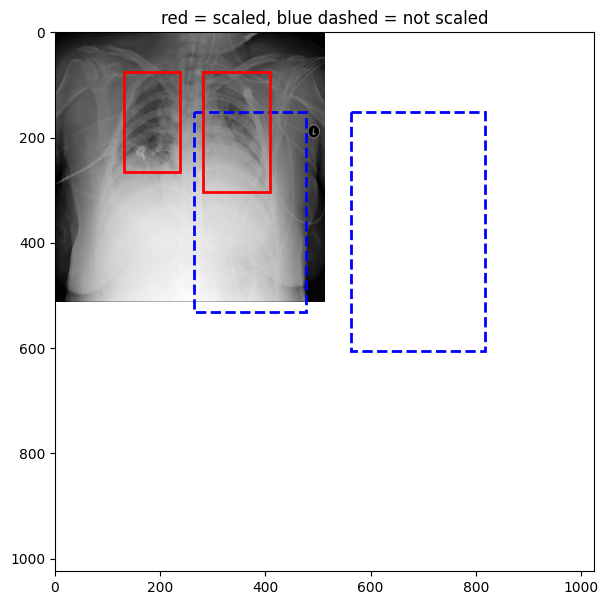

In [12]:
SCALE = 0.5  # 1024 -> 512

img512 = Image.open(f"{OUT_DIR}/{sick_id}.png")
boxes = pos[pos["patientId"] == sick_id]

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(img512, cmap="gray")
for _, r in boxes.iterrows():
    # red: boxes scaled together with the image (correct)
    ax.add_patch(patches.Rectangle((r["x"] * SCALE, r["y"] * SCALE),
                 r["width"] * SCALE, r["height"] * SCALE,
                 fill=False, edgecolor="red", linewidth=2))
    # blue dashed: original boxes, NOT scaled (wrong on purpose)
    ax.add_patch(patches.Rectangle((r["x"], r["y"]), r["width"], r["height"],
                 fill=False, edgecolor="blue", linewidth=2, linestyle="--"))

# show the area up to 1024 so boxes outside the 512 image stay visible
ax.set_xlim(0, 1024)
ax.set_ylim(1024, 0)
ax.set_title("red = scaled, blue dashed = not scaled")
plt.show()

In [13]:
# check that every box fits inside the 1024x1024 image and has a positive size
x2 = pos["x"] + pos["width"]
y2 = pos["y"] + pos["height"]

print("boxes:", len(pos))
print("outside image:", int(((pos["x"] < 0) | (pos["y"] < 0) | (x2 > 1024) | (y2 > 1024)).sum()))
print("non-positive size:", int(((pos["width"] <= 0) | (pos["height"] <= 0)).sum()))
print("smallest side, px:", pos[["width", "height"]].min().min())

boxes: 9555
outside image: 0
non-positive size: 0
smallest side, px: 40.0


## 5: Boxes after resizing

- **Observation:** A converted 512x512 image looks normal, and boxes scaled by 0.5 sit on the lungs. Unscaled boxes shift into the image centre or fall outside the image (checked on one example image).
- **Decision:** Scale x, y, width and height by the same factor as the image. Keep 512x512 as the working size.
- **Result:** All 9555 boxes fit inside the 1024x1024 image, none has non-positive size, the smallest side is 40 px (20 px at 512, 10 px at 256). Not checked yet: how many boxes are small, and whether they hurt detection (hypothesis, not tested).

In [14]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

y_true = val_df["Target"].values
y_pred = np.zeros(len(val_df), dtype=int)  # always "no pneumonia"

print("accuracy: ", round(accuracy_score(y_true, y_pred), 4))
print("recall:   ", round(recall_score(y_true, y_pred), 4))
print("precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))

accuracy:  0.7746
recall:    0.0
precision: 0.0


## 6: Trivial baseline

- **Observation:** A "model" that always predicts "no pneumonia" gets accuracy 0.7746 on val (5337 images), but recall 0.0 and precision 0.0.
- **Decision:** Do not use accuracy as the main metric. Use recall and precision, and for boxes a metric based on IoU (next step). This is row 0 of the results table.
- **Result:** accuracy 0.7746, recall 0.0, precision 0.0 (precision is undefined here, 0/0, and set to 0 with zero_division=0). Seed 42.

In [15]:
def iou(a, b):
    """IoU of two boxes given as (x, y, width, height)."""
    ax2, ay2 = a[0] + a[2], a[1] + a[3]
    bx2, by2 = b[0] + b[2], b[1] + b[3]
    # overlap rectangle (0 if the boxes do not touch)
    ix = max(0, min(ax2, bx2) - max(a[0], b[0]))
    iy = max(0, min(ay2, by2) - max(a[1], b[1]))
    inter = ix * iy
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union

box_a = (0, 0, 100, 100)
box_b = (50, 0, 100, 100)  # same size, shifted right by half the width
print(round(iou(box_a, box_b), 4))

0.3333


In [16]:
cases = [
    ("shifted by 1/3 of width", (0, 0, 90, 100), (30, 0, 90, 100)),
    ("far apart", (0, 0, 100, 100), (200, 0, 100, 100)),
    ("small box inside big box", (0, 0, 100, 100), (25, 25, 50, 50)),
]
for name, a, b in cases:
    print(name, "->", round(iou(a, b), 4))

shifted by 1/3 of width -> 0.5
far apart -> 0.0
small box inside big box -> 0.25


## 7: IoU metric

- **Observation:** IoU = intersection area / union area of two boxes. Shifting a 100x100 box by half its width gives 0.3333, not 0.5. A small box fully inside a big one gives 0.25 (2500 / 10000), so IoU punishes a box that is too big.
- **Decision:** Count a predicted box as a match when IoU >= 0.5. For two same-size boxes shifted sideways, the shift must stay below 1/3 of the width.
- **Result:** iou() checked by hand on 4 cases: 0.3333 (half shift), 0.5 (1/3 shift), 0.0 (far apart), 0.25 (inside). Boxes with zero area do not occur in our data (smallest side is 40 px).

In [17]:
train_ids = set(train_df["patientId"])
val_ids = set(val_df["patientId"])
pos_train = pos[pos["patientId"].isin(train_ids)].copy()
pos_val = pos[pos["patientId"].isin(val_ids)].copy()

# left/right side of the image, decided by the box centre (original 1024 px coordinates)
for d in (pos_train, pos_val):
    d["side"] = np.where(d["x"] + d["width"] / 2 < 512, "left", "right")

# median box per side, computed on train only
med = pos_train.groupby("side")[["x", "y", "width", "height"]].median()
print(med)
print(pos_train["side"].value_counts())

           x      y  width  height
side                              
left   212.0  375.0  212.0   282.0
right  600.0  356.0  225.0   318.0
side
left     4117
right    3540
Name: count, dtype: int64


In [18]:
# for every val box: does the median box of its side reach IoU >= 0.5?
hits = []
for _, r in pos_val.iterrows():
    gt = (r["x"], r["y"], r["width"], r["height"])
    hits.append(iou(gt, tuple(med.loc[r["side"]])) >= 0.5)

print("val boxes:", len(hits))
print("share matched at IoU 0.5:", round(float(np.mean(hits)), 4))

val boxes: 1898
share matched at IoU 0.5: 0.1591


## 8: Fixed-box baseline

- **Observation:** Train has 7657 boxes (4117 on the left half, 3540 on the right half, split by box centre at x=512), val has 1898 (7657 + 1898 = 9555). Median box on train, in 1024 px coordinates: left (x=212, y=375, w=212, h=282), right (x=600, y=356, w=225, h=318).
- **Decision:** Keep this "median box" as a no-learning reference. A trained detector must be compared to it on recall and precision together, because recall alone is easy to raise by drawing many boxes.
- **Result:** On val, the median box of the matching side reaches IoU >= 0.5 for 0.1591 of the 1898 boxes (about 302). Only boxes of sick images were counted, so false boxes on healthy images are not included yet. Rough noise level: about +-0.017, probably a bit more because boxes of one image are correlated. Seed 42.

In [19]:
def evaluate_boxes(pred, gt, thr=0.5):
    """pred, gt: dict {patientId: list of (x, y, w, h)}.
    Each gt box is matched to at most one pred box. Returns tp, fp, fn."""
    tp = fp = fn = 0
    for pid, g_boxes in gt.items():
        p_boxes = pred.get(pid, [])
        used = set()
        for g in g_boxes:
            best_j, best_iou = None, 0.0
            for j, p in enumerate(p_boxes):
                if j in used:
                    continue
                v = iou(g, p)
                if v > best_iou:
                    best_j, best_iou = j, v
            if best_j is not None and best_iou >= thr:
                used.add(best_j)
                tp += 1
            else:
                fn += 1
        fp += len(p_boxes) - len(used)  # pred boxes without a match
    return tp, fp, fn

In [20]:
# gt for ALL val images; healthy images get an empty list
gt = {pid: [] for pid in val_df["patientId"]}
for _, r in pos_val.iterrows():
    gt[r["patientId"]].append((r["x"], r["y"], r["width"], r["height"]))

# baseline: the same two median boxes on every val image
median_pred = [tuple(med.loc["left"]), tuple(med.loc["right"])]
pred = {pid: median_pred for pid in gt}

classes = val_df.set_index("patientId")["class"]
for cls in ["Lung Opacity", "Normal", "No Lung Opacity / Not Normal", "ALL"]:
    ids = list(gt) if cls == "ALL" else list(classes[classes == cls].index)
    tp, fp, fn = evaluate_boxes({i: pred[i] for i in ids}, {i: gt[i] for i in ids})
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    print(f"{cls:30s} images={len(ids):5d} tp={tp:4d} fp={fp:5d} fn={fn:4d} "
          f"precision={prec:.4f} recall={rec:.4f}")

Lung Opacity                   images= 1203 tp= 302 fp= 2104 fn=1596 precision=0.1255 recall=0.1591
Normal                         images= 1770 tp=   0 fp= 3540 fn=   0 precision=0.0000 recall=0.0000
No Lung Opacity / Not Normal   images= 2364 tp=   0 fp= 4728 fn=   0 precision=0.0000 recall=0.0000
ALL                            images= 5337 tp= 302 fp=10372 fn=1596 precision=0.0283 recall=0.1591


## 9: Per-class box metrics for the fixed-box baseline

- **Observation:** Two median boxes drawn on every val image (10674 boxes on 5337 images) give tp=302, fp=10372, fn=1596 (precision 0.0283, recall 0.1591). 8268 of the 10372 false boxes (79.7%) are on healthy images (Normal 3540, Not Normal 4728). On the 1203 sick images alone precision is 0.1255, which is the case "perfect sick/healthy filter + fixed boxes".
- **Decision:** Use this as the reference row for box detection: a model must beat precision 0.0283 and recall 0.1591 together. Even a perfect sick/healthy filter would leave recall at 0.1591 with fixed boxes, so the boxes themselves must be learned.
- **Result:** ALL: precision 0.0283, recall 0.1591 (seed 42). For Normal / Not Normal there are no true boxes, so recall is undefined (0/0, shown as 0.0). Rough noise: recall about +-0.017, precision about +-0.003. The Not Normal confusion hypothesis is not tested here, because this baseline draws boxes on every image regardless of its content.

In [21]:
RESULTS_CSV = "/kaggle/working/results.csv"

# ground truth boxes for ALL val images (healthy images get an empty list)
gt = {pid: [] for pid in val_df["patientId"]}
for _, r in pos_val.iterrows():
    gt[r["patientId"]].append((r["x"], r["y"], r["width"], r["height"]))
classes = val_df.set_index("patientId")["class"]


def score_by_class(experiment, pred):
    """Box metrics on val, per class and for all images. pred: {patientId: list of boxes}."""
    rows = []
    for cls in ["Lung Opacity", "Normal", "No Lung Opacity / Not Normal", "ALL"]:
        ids = list(gt) if cls == "ALL" else list(classes[classes == cls].index)
        tp, fp, fn = evaluate_boxes({i: pred.get(i, []) for i in ids}, {i: gt[i] for i in ids})
        rows.append({
            "experiment": experiment, "class": cls, "images": len(ids),
            "tp": tp, "fp": fp, "fn": fn,
            # 0/0 is shown as 0.0 (undefined, not a real measurement)
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "recall": tp / (tp + fn) if tp + fn else 0.0,
            "seed": SEED,
        })
    return pd.DataFrame(rows)


def save_result(new_rows):
    """Add rows to results.csv; re-running an experiment replaces its old rows."""
    if os.path.exists(RESULTS_CSV):
        old = pd.read_csv(RESULTS_CSV)
        old = old[~old["experiment"].isin(new_rows["experiment"].unique())]
        new_rows = pd.concat([old, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_CSV, index=False)
    return new_rows


# 00: draws no boxes at all (the "always no pneumonia" baseline, in box terms)
r0 = score_by_class("00_no_boxes", {})
# 01: the two median boxes on every image
median_pred = [tuple(med.loc["left"]), tuple(med.loc["right"])]
r1 = score_by_class("01_median_boxes", {pid: median_pred for pid in gt})

table = save_result(pd.concat([r0, r1], ignore_index=True))
print(table.round(4).to_string(index=False))

     experiment                        class  images  tp    fp   fn  precision  recall  seed
    00_no_boxes                 Lung Opacity    1203   0     0 1898     0.0000  0.0000    42
    00_no_boxes                       Normal    1770   0     0    0     0.0000  0.0000    42
    00_no_boxes No Lung Opacity / Not Normal    2364   0     0    0     0.0000  0.0000    42
    00_no_boxes                          ALL    5337   0     0 1898     0.0000  0.0000    42
01_median_boxes                 Lung Opacity    1203 302  2104 1596     0.1255  0.1591    42
01_median_boxes                       Normal    1770   0  3540    0     0.0000  0.0000    42
01_median_boxes No Lung Opacity / Not Normal    2364   0  4728    0     0.0000  0.0000    42
01_median_boxes                          ALL    5337 302 10372 1596     0.0283  0.1591    42


## 10: Results table

- **Observation:** Two reference rows for box detection on val (seed 42), saved per class to results.csv. 00_no_boxes (draws nothing): ALL tp=0, fp=0, fn=1898, recall 0.0, precision undefined (0/0, shown as 0.0). 01_median_boxes: ALL tp=302, fp=10372, fn=1596, precision 0.0283, recall 0.1591.
- **Decision:** Every next experiment adds its rows with score_by_class() and save_result(), so all runs are compared on the same metric, per class and for ALL. Re-running an experiment replaces its old rows.
- **Result:** Sanity check passed: tp + fn = 1898 in both experiments (the number of true val boxes). In Normal / Not Normal there are no true boxes, so recall there is undefined (0/0, shown as 0.0).

In [22]:
import torch
import torchvision

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("cuda available:", torch.cuda.is_available())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(i, p.name, round(p.total_memory / 1e9, 1), "GB")

torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
cuda available: True
0 Tesla T4 15.6 GB
1 Tesla T4 15.6 GB


In [23]:
import torch
from torch.utils.data import Dataset

IMG_SIZE = 256
torch.manual_seed(SEED)

# read the saved split so this cell works after a restart
train_df = pd.read_csv("train_split.csv")
val_df = pd.read_csv("val_split.csv")

class CxrDataset(Dataset):
    """Returns (image tensor 1 x H x W with values 0..1, label 0/1)."""
    def __init__(self, df, img_dir=OUT_DIR, size=IMG_SIZE):
        self.ids = df["patientId"].tolist()
        self.labels = df["Target"].tolist()
        self.img_dir = img_dir
        self.size = size

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = Image.open(f"{self.img_dir}/{self.ids[i]}.png").convert("L")
        img = img.resize((self.size, self.size), Image.BILINEAR)
        x = torch.from_numpy(np.array(img, dtype=np.float32) / 255.0).unsqueeze(0)
        return x, self.labels[i]

train_ds = CxrDataset(train_df)
val_ds = CxrDataset(val_df)

x, y = train_ds[0]
print("sizes:", len(train_ds), len(val_ds))
print("shape:", tuple(x.shape), "min/max:", round(x.min().item(), 4), round(x.max().item(), 4), "label:", y)

sizes: 21347 5337
shape: (1, 256, 256) min/max: 0.0 0.949 label: 0


In [24]:
import torchvision

torch.manual_seed(SEED)  # same starting weights for the new last layer on every run

# needs Internet ON in Kaggle settings to download pretrained weights
model = torchvision.models.resnet18(weights="IMAGENET1K_V1")
model.fc = torch.nn.Linear(model.fc.in_features, 1)  # one output: "sick" score

xb = torch.stack([train_ds[i][0] for i in range(4)])  # 4 images, 1 channel
xb3 = xb.repeat(1, 3, 1, 1)  # copy the gray channel 3 times

with torch.no_grad():  # just a test pass, no training
    out = model(xb3)

print("input:", tuple(xb3.shape))
print("output:", tuple(out.shape))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s]


input: (4, 3, 256, 256)
output: (4, 1)


In [25]:
import random
from torch.utils.data import DataLoader
from sklearn.metrics import average_precision_score

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)  # should be "cuda": turn on GPU in Kaggle settings

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def make_model():
    m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
    m.fc = torch.nn.Linear(m.fc.in_features, 1)  # one output: "sick" score
    return m.to(DEVICE)

def predict(model, loader):
    """Returns a 'sick' probability (0..1) for every image in the loader."""
    model.eval()
    scores = []
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(DEVICE).repeat(1, 3, 1, 1)  # 1 gray channel -> 3 channels
            scores.append(torch.sigmoid(model(x)).squeeze(1).cpu())
    return torch.cat(scores).numpy()

def report(name, scores, df, thr=0.5, path="results_classifier.csv"):
    """Overall metrics + share called 'sick' in each class. Saves to a CSV."""
    y = df["Target"].values
    pred = (scores >= thr).astype(int)
    rows = [{"experiment": name, "group": "ALL", "images": len(y),
             "pr_auc": round(average_precision_score(y, scores), 4),
             "recall": round(recall_score(y, pred), 4),
             "precision": round(precision_score(y, pred, zero_division=0), 4),
             "share_called_sick": round(pred.mean(), 4)}]
    for cls in ["Lung Opacity", "Normal", "No Lung Opacity / Not Normal"]:
        m = (df["class"] == cls).values
        rows.append({"experiment": name, "group": cls, "images": int(m.sum()),
                     "share_called_sick": round(pred[m].mean(), 4)})
    new = pd.DataFrame(rows)
    if os.path.exists(path):  # replace old rows of the same experiment, keep others
        old = pd.read_csv(path)
        new = pd.concat([old[old["experiment"] != name], new])
    new.to_csv(path, index=False)
    return pd.DataFrame(rows)

device: cuda


In [26]:
def train_classifier(cfg):
    set_seed(cfg["seed"])
    g = torch.Generator().manual_seed(cfg["seed"])  # same shuffle order on every run
    train_loader = DataLoader(CxrDataset(train_df, size=cfg["size"]), batch_size=cfg["batch_size"],
                              shuffle=True, num_workers=2, generator=g)
    val_loader = DataLoader(CxrDataset(val_df, size=cfg["size"]), batch_size=cfg["batch_size"],
                            shuffle=False, num_workers=2)

    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    pw = torch.tensor([cfg["pos_weight"]], device=DEVICE) if cfg["pos_weight"] else None
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pw)

    for epoch in range(cfg["epochs"]):
        model.train()
        total = 0.0
        for x, y in tqdm(train_loader, desc=f"epoch {epoch + 1}"):
            x = x.to(DEVICE).repeat(1, 3, 1, 1)
            y = y.float().to(DEVICE)
            loss = loss_fn(model(x).squeeze(1), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(y)
        scores = predict(model, val_loader)
        print(f"epoch {epoch + 1}: train loss {total / len(train_loader.dataset):.4f}, "
              f"val PR-AUC {average_precision_score(val_df['Target'], scores):.4f}")
    return model, scores

In [27]:
EXP1 = {"name": "exp1_resnet18_256_noweight", "seed": 42, "size": 256,
        "epochs": 3, "batch_size": 32, "lr": 0.0001, "pos_weight": None}

model_exp1, scores_exp1 = train_classifier(EXP1)
report(EXP1["name"], scores_exp1, val_df)

epoch 1: 100%|██████████| 668/668 [01:32<00:00,  7.21it/s]


epoch 1: train loss 0.3820, val PR-AUC 0.6613


epoch 2: 100%|██████████| 668/668 [01:36<00:00,  6.90it/s]


epoch 2: train loss 0.3362, val PR-AUC 0.7006


epoch 3: 100%|██████████| 668/668 [01:38<00:00,  6.79it/s]


epoch 3: train loss 0.2917, val PR-AUC 0.6655


,experiment,group,images,pr_auc,recall,precision,share_called_sick
0,exp1_resnet18_256_noweight,ALL,5337,0.6655,0.6351,0.5927,0.2415
1,exp1_resnet18_256_noweight,Lung Opacity,1203,NaN,NaN,NaN,0.6351
2,exp1_resnet18_256_noweight,Normal,1770,NaN,NaN,NaN,0.0085
3,exp1_resnet18_256_noweight,No Lung Opacity / Not Normal,2364,NaN,NaN,NaN,0.2157


## 11: Classifier, ResNet18, 256 px, no class weight
- Setup: pretrained ResNet18, gray channel copied to 3, Adam lr 0.0001, batch 32, 3 epochs, seed 42. Random classifier reference: PR-AUC 0.2254.
- Result (last epoch): val PR-AUC 0.6655, recall 0.6351, precision 0.5927 at threshold 0.5. The model calls 24.15% of images sick (true share 22.54%), so no "always healthy" collapse without class weights.
- Per class: called sick Normal 0.0085, Not Normal about 0.216, so almost all false alarms come from Not Normal. This supports the hypothesis from step 1.
- PR-AUC by epoch: 0.6613, 0.7006, 0.6655 while train loss kept falling. Could be early overfitting or noise; one run cannot tell.

In [28]:
EXP1_S43 = {"name": "exp1_resnet18_256_noweight_seed43", "seed": 43, "size": 256,
            "epochs": 3, "batch_size": 32, "lr": 0.0001, "pos_weight": None}

model_exp1_s43, scores_exp1_s43 = train_classifier(EXP1_S43)
report(EXP1_S43["name"], scores_exp1_s43, val_df)

epoch 1: 100%|██████████| 668/668 [01:38<00:00,  6.80it/s]


epoch 1: train loss 0.3810, val PR-AUC 0.6839


epoch 2: 100%|██████████| 668/668 [01:38<00:00,  6.81it/s]


epoch 2: train loss 0.3373, val PR-AUC 0.6855


epoch 3: 100%|██████████| 668/668 [01:38<00:00,  6.79it/s]


epoch 3: train loss 0.2951, val PR-AUC 0.6913


,experiment,group,images,pr_auc,recall,precision,share_called_sick
0,exp1_resnet18_256_noweight_seed43,ALL,5337,0.6913,0.3948,0.78,0.1141
1,exp1_resnet18_256_noweight_seed43,Lung Opacity,1203,NaN,NaN,NaN,0.3948
2,exp1_resnet18_256_noweight_seed43,Normal,1770,NaN,NaN,NaN,0.0006
3,exp1_resnet18_256_noweight_seed43,No Lung Opacity / Not Normal,2364,NaN,NaN,NaN,0.0563


## 12: Classifier, seed 43
- Val PR-AUC by epoch: 0.6839, 0.6855, 0.6913 (seed 42 ended at 0.6655). Seed alone moves PR-AUC by about 0.03, so smaller differences between single runs are treated as noise.
- The epoch 2 > epoch 3 drop from seed 42 did not repeat; no clear sign of overfitting.
- At threshold 0.5, recall changed from 0.6351 to 0.3948 with similar PR-AUC: the fixed threshold is unstable, so models are compared by PR-AUC.
- False alarms again come almost only from Not Normal (about 133 of 134).
- Next: the classifier only says *whether* an image is sick, but the task asks *where*.
  Move to a detector: YOLOv8n (ultralytics) learns boxes and healthy images (no boxes) in one model,
  so it can be compared directly with the fixed-box baseline from steps 8–10.

In [29]:
import yaml

YOLO_DIR = "/kaggle/working/yolo"
boxes_by_id = {pid: g[["x", "y", "width", "height"]].values for pid, g in pos.groupby("patientId")}

for split, df in [("train", train_df), ("val", val_df)]:
    img_dir, lbl_dir = f"{YOLO_DIR}/images/{split}", f"{YOLO_DIR}/labels/{split}"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    for pid in df["patientId"]:
        dst = f"{img_dir}/{pid}.png"
        if not os.path.exists(dst):
            os.link(f"{OUT_DIR}/{pid}.png", dst)  # hard link: no extra disk space
        # YOLO format: class cx cy w h, all divided by image size (1024 in original coords)
        lines = [f"0 {(x + w / 2) / 1024:.6f} {(y + h / 2) / 1024:.6f} {w / 1024:.6f} {h / 1024:.6f}"
                 for x, y, w, h in boxes_by_id.get(pid, [])]
        with open(f"{lbl_dir}/{pid}.txt", "w") as f:  # empty file = healthy image
            f.write("\n".join(lines))

with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    yaml.safe_dump({"path": YOLO_DIR, "train": "images/train", "val": "images/val",
                    "names": {0: "opacity"}}, f)

for split in ["train", "val"]:
    n_img = len(os.listdir(f"{YOLO_DIR}/images/{split}"))
    n_box = sum(len(open(f"{YOLO_DIR}/labels/{split}/{p}").read().splitlines())
                for p in os.listdir(f"{YOLO_DIR}/labels/{split}"))
    print(split, "images:", n_img, "boxes:", n_box)

train images: 21347 boxes: 7657
val images: 5337 boxes: 1898


centre (0.362, 0.333), size (0.208 x 0.370)
centre (0.674, 0.370), size (0.250 x 0.442)


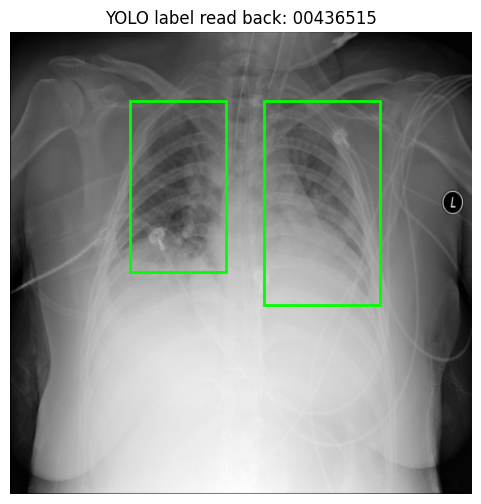

In [30]:
# Sanity check: read one YOLO label file back and draw it on its image
split = "train" if sick_id in set(train_df["patientId"]) else "val"
img = Image.open(f"{YOLO_DIR}/images/{split}/{sick_id}.png")
W, H = img.size  # 512 x 512

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")
for line in open(f"{YOLO_DIR}/labels/{split}/{sick_id}.txt").read().splitlines():
    _, cx, cy, w, h = map(float, line.split())
    # YOLO stores the box centre and size as shares of the image (0..1)
    ax.add_patch(patches.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H,
                                   fill=False, edgecolor="lime", linewidth=2))
    print(f"centre ({cx:.3f}, {cy:.3f}), size ({w:.3f} x {h:.3f})")
ax.set_title(f"YOLO label read back: {sick_id[:8]}")
ax.axis("off")
plt.show()

In [31]:
!pip install -q ultralytics==8.3.40

In [32]:
os.environ["YOLO_VERBOSE"] = "False"

from ultralytics import YOLO
import ultralytics.utils.callbacks.raytune as raytune_cb

raytune_cb.callbacks.clear()  # Kaggle's Ray version breaks this callback; we do not use Ray

YOLO_DIR = "/kaggle/working/yolo"
assert os.path.exists(f"{YOLO_DIR}/data.yaml"), "Run the YOLO data preparation cell first"

DET1 = {"name": "det1_yolov8n_512", "model": "yolov8n.pt", "imgsz": 512,
        "epochs": 10, "batch": 32, "seed": 42}

det1 = YOLO(DET1["model"])
_ = det1.train(data=f"{YOLO_DIR}/data.yaml", imgsz=DET1["imgsz"], epochs=DET1["epochs"],
           batch=DET1["batch"], seed=DET1["seed"], deterministic=True, workers=2,
           project="/kaggle/working/runs", name=DET1["name"], exist_ok=True)

hist = pd.read_csv(f"/kaggle/working/runs/{DET1['name']}/results.csv")
hist.columns = hist.columns.str.strip()  # older ultralytics adds spaces to column names
print(hist[["epoch", "metrics/mAP50(B)"]].round(3).to_string(index=False))

100%|██████████| 6.25M/6.25M [00:00<00:00, 109MB/s]
100%|██████████| 755k/755k [00:00<00:00, 27.6MB/s]
I0000 00:00:1795094538.730388      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
100%|██████████| 5.35M/5.35M [00:00<00:00, 90.3MB/s]
/usr/local/lib/python3.13/dist-packages/ultralytics/data/augment.py:1850: UserWarning: Argument(s) 'quality_lower' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=75, p=0.0),
/usr/local/lib/python3.13/dist-packages/ultralytics/data/augment.py:1850: UserWarning: Argument(s) 'quality_lower' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=75, p=0.0),


 epoch  metrics/mAP50(B)
     1             0.115
     2             0.252
     3             0.086
     4             0.167
     5             0.261
     6             0.292
     7             0.331
     8             0.340
     9             0.351
    10             0.358


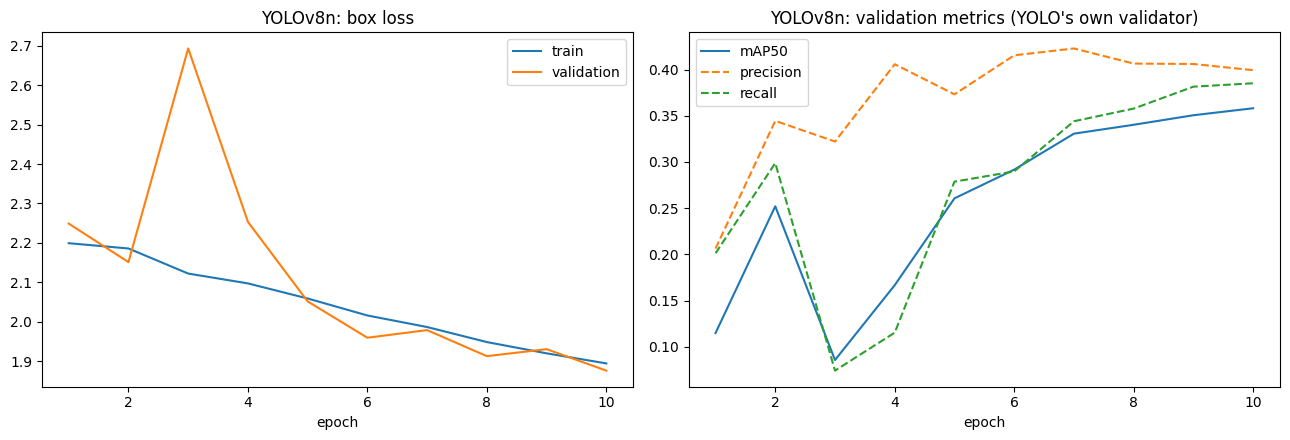

In [33]:
hist = pd.read_csv(f"/kaggle/working/runs/{DET1['name']}/results.csv")
hist.columns = hist.columns.str.strip()  # older ultralytics adds spaces to column names

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.epoch, hist["train/box_loss"], label="train")
axes[0].plot(hist.epoch, hist["val/box_loss"], label="validation")
axes[0].set(title="YOLOv8n: box loss", xlabel="epoch")
axes[0].legend()
axes[1].plot(hist.epoch, hist["metrics/mAP50(B)"], label="mAP50")
axes[1].plot(hist.epoch, hist["metrics/precision(B)"], label="precision", linestyle="--")
axes[1].plot(hist.epoch, hist["metrics/recall(B)"], label="recall", linestyle="--")
axes[1].set(title="YOLOv8n: validation metrics (YOLO's own validator)", xlabel="epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig("det1_curves.png", dpi=120)
plt.show()

In [34]:
det1_best = YOLO("/kaggle/working/runs/det1_yolov8n_512/weights/best.pt")
val_paths = [f"{YOLO_DIR}/images/val/{pid}.png" for pid in val_df["patientId"]]
SCALE_UP = 1024 / 512  # predictions are in 512 px, ground truth in 1024 px
CHUNK = 32  # a list of paths is one batch for YOLO, so feed it in small chunks

det1_raw = {}  # patientId -> list of (confidence, (x, y, w, h)) in 1024 px coords
for start in tqdm(range(0, len(val_paths), CHUNK)):
    for res in det1_best.predict(val_paths[start:start + CHUNK], imgsz=512, conf=0.01, verbose=False):
        pid = os.path.splitext(os.path.basename(res.path))[0]
        boxes = []
        for (x1, y1, x2, y2), c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()):
            boxes.append((float(c), (x1 * SCALE_UP, y1 * SCALE_UP,
                                     (x2 - x1) * SCALE_UP, (y2 - y1) * SCALE_UP)))
        det1_raw[pid] = boxes

print("images:", len(det1_raw), "boxes with confidence >= 0.01:", sum(len(b) for b in det1_raw.values()))

100%|██████████| 167/167 [01:01<00:00,  2.73it/s]

images: 5337 boxes with confidence >= 0.01: 28007


In [35]:
def box_report(name, raw, conf_thr, path="results_boxes.csv"):
    """Per-class tp/fp/fn at IoU 0.5 for boxes with confidence >= conf_thr. Saves to a CSV."""
    pred = {pid: [b for c, b in raw.get(pid, []) if c >= conf_thr] for pid in gt}
    rows = []
    for cls in ["Lung Opacity", "Normal", "No Lung Opacity / Not Normal", "ALL"]:
        ids = list(gt) if cls == "ALL" else list(classes[classes == cls].index)
        tp, fp, fn = evaluate_boxes({i: pred[i] for i in ids}, {i: gt[i] for i in ids})
        rows.append({"experiment": name, "conf": conf_thr, "group": cls, "tp": tp, "fp": fp, "fn": fn,
                     "precision": round(tp / (tp + fp), 4) if tp + fp else 0.0,
                     "recall": round(tp / (tp + fn), 4) if tp + fn else 0.0})
    new = pd.DataFrame(rows)
    if os.path.exists(path):  # replace old rows of the same experiment and threshold
        old = pd.read_csv(path)
        new = pd.concat([old[~((old["experiment"] == name) & (old["conf"] == conf_thr))], new])
    new.to_csv(path, index=False)
    return pd.DataFrame(rows)

median_raw = {pid: [(1.0, b) for b in median_pred] for pid in gt}
tables = [box_report("median_box_baseline", median_raw, 0.0)]
for thr in [0.1, 0.25, 0.5]:
    tables.append(box_report(DET1["name"], det1_raw, thr))
pd.concat(tables).reset_index(drop=True)

,experiment,conf,group,tp,fp,fn,precision,recall
0,median_box_baseline,0.00,Lung Opacity,302,2104,1596,0.1255,0.1591
1,median_box_baseline,0.00,Normal,0,3540,0,0.0000,0.0000
2,median_box_baseline,0.00,No Lung Opacity / Not Normal,0,4728,0,0.0000,0.0000
3,median_box_baseline,0.00,ALL,302,10372,1596,0.0283,0.1591
4,det1_yolov8n_512,0.10,Lung Opacity,851,898,1047,0.4866,0.4484
5,det1_yolov8n_512,0.10,Normal,0,4,0,0.0000,0.0000
6,det1_yolov8n_512,0.10,No Lung Opacity / Not Normal,0,607,0,0.0000,0.0000
7,det1_yolov8n_512,0.10,ALL,851,1509,1047,0.3606,0.4484
8,det1_yolov8n_512,0.25,Lung Opacity,291,81,1607,0.7823,0.1533
9,det1_yolov8n_512,0.25,Normal,0,0,0,0.0000,0.0000


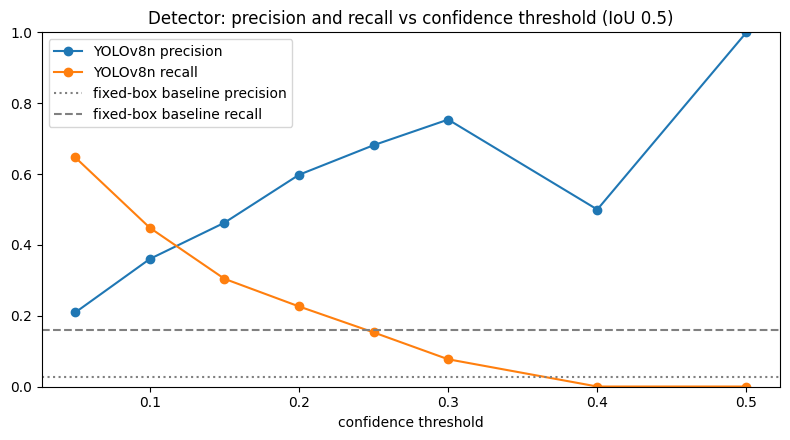

 conf  precision  recall
 0.05      0.210   0.647
 0.10      0.361   0.448
 0.15      0.463   0.305
 0.20      0.598   0.227
 0.25      0.681   0.153
 0.30      0.754   0.077
 0.40      0.500   0.001
 0.50      1.000   0.001


In [36]:
# Our metric (IoU 0.5) at several confidence thresholds: the precision / recall trade-off
thresholds = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
rows = []
for thr in thresholds:
    pred = {pid: [b for c, b in det1_raw.get(pid, []) if c >= thr] for pid in gt}
    tp, fp, fn = evaluate_boxes(pred, gt)
    rows.append({"conf": thr, "precision": tp / (tp + fp) if tp + fp else np.nan,  # no boxes -> undefined
                 "recall": tp / (tp + fn)})
curve = pd.DataFrame(rows)
b_tp, b_fp, b_fn = evaluate_boxes({pid: median_pred for pid in gt}, gt)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve.conf, curve.precision, marker="o", label="YOLOv8n precision")
ax.plot(curve.conf, curve.recall, marker="o", label="YOLOv8n recall")
ax.axhline(b_tp / (b_tp + b_fp), color="gray", linestyle=":", label="fixed-box baseline precision")
ax.axhline(b_tp / (b_tp + b_fn), color="gray", linestyle="--", label="fixed-box baseline recall")
ax.set(title="Detector: precision and recall vs confidence threshold (IoU 0.5)",
       xlabel="confidence threshold", ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.savefig("det1_conf_tradeoff.png", dpi=120)
plt.show()
print(curve.round(3).to_string(index=False))

## 13: Detector, YOLOv8n, 512 px, 10 epochs, seed 42
- Data: the same train/val split, boxes converted to YOLO format (box centre, width, height divided by 1024),
  one label file per image; healthy images get an empty file. One label file was read back and drawn:
  the boxes match step 5.
- mAP50 (YOLO validator) rose from 0.149 (epoch 1) to about 0.36 and was flat over epochs 8-10. Mosaic augmentation was off for all epochs (close_mosaic=10).
- Our metric (IoU 0.5), confidence 0.1: precision 0.3538, recall 0.4758 vs median-box baseline 0.0283 / 0.1591. Both clearly better, beyond noise.
- Confidence 0.25: precision 0.6963, recall 0.1486. At 0.5 the model outputs no boxes: its confidences are low.
- False boxes on healthy images: Normal 5, Not Normal 740 (conf 0.1). Same confusion as the classifier, so it is a property of the data, not of one model.
- 904 of 1649 false boxes are on sick images: wrong position or extra boxes.

hits: 611 misses: 469 Not Normal false alarms: 355


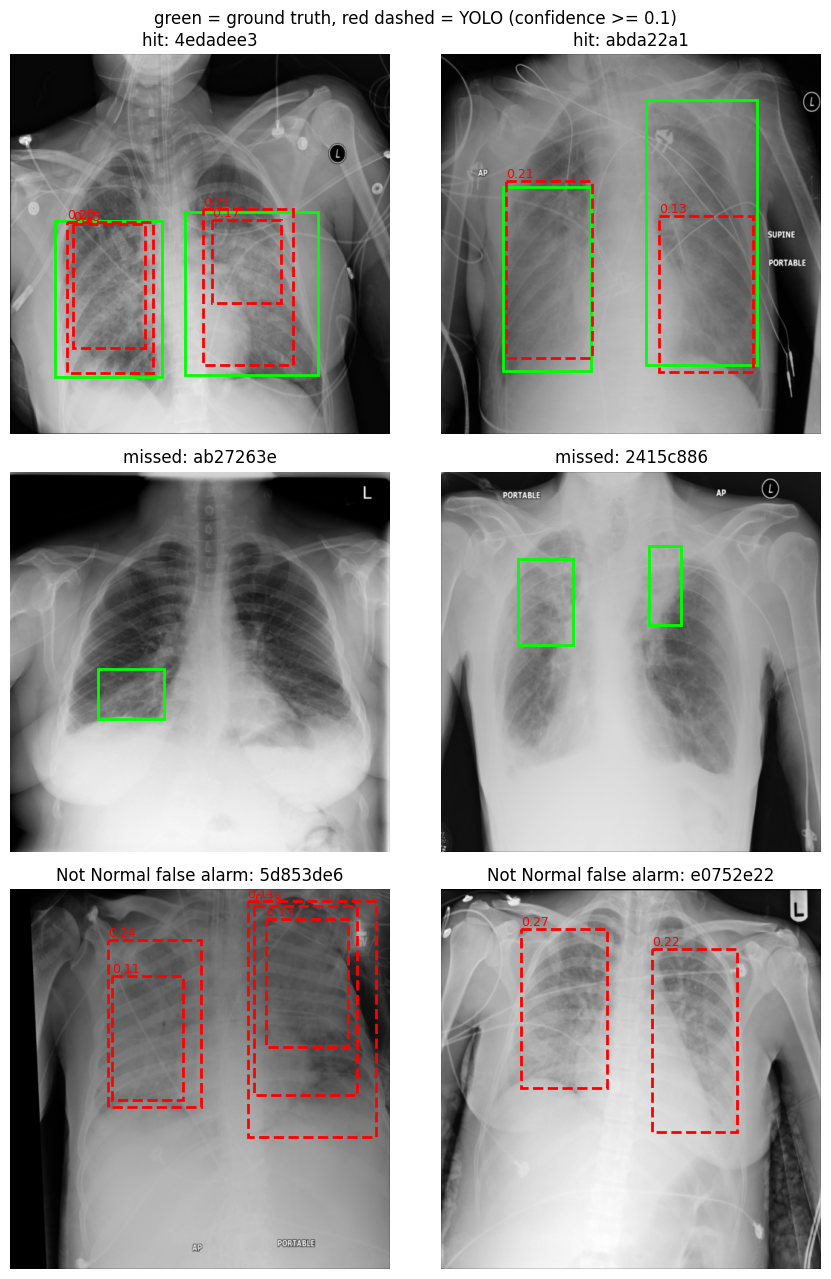

In [37]:
CONF = 0.1
S = 0.5  # boxes are in 1024 px, images are 512 px
rng = np.random.RandomState(SEED)

def kept(pid):
    return [b for c, b in det1_raw[pid] if c >= CONF]

lo_ids = list(classes[classes == "Lung Opacity"].index)
nn_ids = list(classes[classes == "No Lung Opacity / Not Normal"].index)
hits = [p for p in lo_ids if evaluate_boxes({p: kept(p)}, {p: gt[p]})[0] > 0]  # at least one correct box
misses = [p for p in lo_ids if not kept(p)]                                      # sick, but no box at all
false_alarms = [p for p in nn_ids if kept(p)]                                    # Not Normal with a box
print("hits:", len(hits), "misses:", len(misses), "Not Normal false alarms:", len(false_alarms))

picks = ([("hit", p) for p in rng.choice(hits, 2, replace=False)]
         + [("missed", p) for p in rng.choice(misses, 2, replace=False)]
         + [("Not Normal false alarm", p) for p in rng.choice(false_alarms, 2, replace=False)])

fig, axes = plt.subplots(3, 2, figsize=(9, 13))
for ax, (title, pid) in zip(axes.flat, picks):
    ax.imshow(Image.open(f"{OUT_DIR}/{pid}.png"), cmap="gray")
    for x, y, w, h in gt[pid]:
        ax.add_patch(patches.Rectangle((x * S, y * S), w * S, h * S,
                                       fill=False, edgecolor="lime", linewidth=2))
    for c, (x, y, w, h) in det1_raw[pid]:
        if c >= CONF:
            ax.add_patch(patches.Rectangle((x * S, y * S), w * S, h * S, fill=False,
                                           edgecolor="red", linewidth=2, linestyle="--"))
            ax.text(x * S, y * S - 4, f"{c:.2f}", color="red", fontsize=9)
    ax.set_title(f"{title}: {pid[:8]}")
    ax.axis("off")

fig.suptitle("green = ground truth, red dashed = YOLO (confidence >= 0.1)")
plt.tight_layout()
plt.savefig("examples_det1.png", dpi=100)
plt.show()

## 14: Detector examples (confidence 0.1)
- Of 1203 sick val images: 646 get at least one correct box, 414 get no box at all, the other 143 get boxes only in wrong places. 437 Not Normal images get a false box.
- Hits: confidences are low (0.13-0.32), and the model often draws two overlapping boxes on the same area. The extra box counts as false, which explains part of the false boxes on sick images.
- Misses: both shown examples have small true boxes, which supports the hypothesis from step 5 that small boxes are harder (2 examples only, not measured).
- Not Normal false alarms: boxes sit on hazy lower-lung areas that look like opacity, the same confusion as in the classifier.
- Not done (possible next steps): longer training or a larger model, merging overlapping boxes, recall by box size.

In [38]:
import shutil

# temporary files: converted PNGs and the YOLO copy of the dataset (~2.5 GB)
for d in ["/kaggle/working/png512", "/kaggle/working/yolo"]:
    shutil.rmtree(d, ignore_errors=True)
print(sorted(os.listdir("/kaggle/working")))

['__notebook__.ipynb', 'det1_conf_tradeoff.png', 'det1_curves.png', 'examples_det1.png', 'results.csv', 'results_boxes.csv', 'results_classifier.csv', 'runs', 'train_split.csv', 'val_split.csv', 'yolo11n.pt', 'yolov8n.pt']
